# 03 · Modelo: ¿qué pedidos llegarán tarde?

**Objetivo:** al momento de la compra, ordenar los pedidos por riesgo de no llegar a tiempo, para actuar sobre los más riesgosos (ajustar la fecha prometida o priorizar el envío).

**Protocolo:**

| Paso | Detalle |
|---|---|
| Candidatos | Una regla simple, regresión logística y gradient boosting |
| Selección | Se elige con un periodo de **validación**: compras de enero a marzo de 2018 |
| Prueba | Se reporta una sola vez en el periodo de **prueba**: compras de abril a agosto de 2018, con intervalos de confianza por bootstrap |
| Estabilidad | Un **backtest mes a mes** comprueba que el resultado no depende de un solo corte |
| Datos de entrenamiento | En cada corte, solo pedidos cuyo resultado ya se conocía antes del inicio del periodo evaluado |

**Métrica principal:** % de los pedidos tardíos capturados al revisar el 10% de pedidos más riesgosos. Responde directamente a la pregunta de negocio: si el equipo de logística solo puede atender 1 de cada 10 pedidos, ¿cuántos retrasos alcanza a prevenir? Como apoyo se reportan AUC-PR (adecuada para clases desbalanceadas) y AUC-ROC.

In [1]:
import json
import sys
import warnings
from dataclasses import asdict, dataclass

sys.path.insert(0, "../src")
warnings.filterwarnings("ignore", category=FutureWarning)

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from features import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET, build_features, load_model_base
from plot_style import AQUA, BLUE, GRAY, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"


@dataclass
class Config:
    seed: int = 42
    val_start: str = "2018-01-01"
    test_start: str = "2018-04-01"
    test_end: str = "2018-09-01"
    capacity: float = 0.10          # % de pedidos que el equipo puede atender
    n_bootstrap: int = 1000
    backtest_first_month: str = "2017-10-01"


cfg = Config()
np.random.seed(cfg.seed)
df = load_model_base("../data/processed/model_base.csv")

## 1. Candidatos

- **Regla simple:** ordenar por `promise_ratio` de menor a mayor. Los pedidos con el colchón más corto (días prometidos ÷ días históricos de la ruta) son los más riesgosos. No se entrena; solo usa historia.
- **Regresión logística:** 26 variables; escalado e imputación dentro de un `Pipeline` y codificación one-hot de las categóricas.
- **Gradient boosting** (`HistGradientBoostingClassifier` de scikit-learn, la misma técnica de árboles por histogramas que XGBoost y LightGBM): manejo nativo de categóricas y regularización moderada.

In [2]:
def make_logistic() -> Pipeline:
    pre = ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL_FEATURES),
    ])
    return make_pipeline(pre, LogisticRegression(max_iter=3000, C=0.5))


def to_boosting_frame(train: pd.DataFrame, other: pd.DataFrame):
    """Convierte las categóricas a 'category' con las categorías vistas SOLO en entrenamiento."""
    a, b = train[FEATURES].copy(), other[FEATURES].copy()
    for col in CATEGORICAL_FEATURES:
        cats = pd.Index(a[col].dropna().unique())
        a[col] = pd.Categorical(a[col], categories=cats)
        b[col] = pd.Categorical(b[col].where(b[col].isin(cats)), categories=cats)
    return a, b


def make_boosting(seed: int) -> HistGradientBoostingClassifier:
    return HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=200,
        l2_regularization=1.0, categorical_features="from_dtype",
        early_stopping=False, random_state=seed,
    )


def split_at(start: pd.Timestamp, end: pd.Timestamp):
    """
    Construye variables con priors calculados antes de `start` y separa:
    - train: pedidos cuyo RESULTADO se conocía antes de `start`
    - evaluación: pedidos COMPRADOS en [start, end)
    Auditoría de fuga: ningún pedido de entrenamiento tiene un resultado
    posterior al inicio del periodo evaluado, y ningún pedido evaluado está
    en entrenamiento (todos se compraron en o después de `start`).
    """
    X = build_features(df, cutoff=start)
    train = X[X.outcome_known_ts < start]
    evaluation = X[(X.purchase_ts >= start) & (X.purchase_ts < end)]
    assert train.order_id.isin(evaluation.order_id).sum() == 0
    return train, evaluation


def score_all(train: pd.DataFrame, evaluation: pd.DataFrame, seed: int = 42):
    """Devuelve puntajes de riesgo (mayor = más riesgo) de los tres candidatos."""
    logistic = make_logistic().fit(train[FEATURES], train[TARGET])
    a, b = to_boosting_frame(train, evaluation)
    boosting = make_boosting(seed).fit(a, train[TARGET])
    scores = {
        "Regla: colchón del plazo": -evaluation["promise_ratio"].to_numpy(),
        "Regresión logística": logistic.predict_proba(evaluation[FEATURES])[:, 1],
        "Gradient boosting": boosting.predict_proba(b)[:, 1],
    }
    return scores, {"logistic": logistic, "boosting": boosting}


def capture_at(y: np.ndarray, score: np.ndarray, k: float) -> float:
    """% de los positivos que caen en el k% de pedidos con mayor puntaje."""
    n = int(round(len(score) * k))
    top = np.argsort(-score, kind="stable")[:n]
    return y[top].sum() / y.sum()


def metrics(y: np.ndarray, score: np.ndarray, k: float) -> dict:
    return {
        "captura_top10": capture_at(y, score, k),
        "precision_top10": y[np.argsort(-score, kind="stable")[: int(round(len(score) * k))]].mean(),
        "auc_pr": average_precision_score(y, score),
        "auc_roc": roc_auc_score(y, score),
    }

## 2. Decisión previa: ¿historial de la ruta acumulado o reciente?

`promise_ratio` divide los días prometidos entre lo que **históricamente** tarda la ruta. En 2018 las entregas se aceleraron mucho, así que el promedio acumulado desde 2017 hace ver lentas a rutas que ya no lo son.

Se comparan varias ventanas **solo en el periodo de validación**, usando la regla tal cual. La ventana elegida (90 días) es la que usa `src/features.py`.

In [3]:
import features as feat

val_start, val_end = pd.Timestamp(cfg.val_start), pd.Timestamp(cfg.test_start)
Xv = build_features(df, cutoff=val_start)
in_val = (Xv.purchase_ts >= val_start) & (Xv.purchase_ts < val_end)
global_days = Xv.loc[Xv.delivered_ts < val_start, "actual_days"].mean()
window_rows = []
for label, days in [("Acumulado (todo el historial)", 10_000), ("Últimos 180 días", 180),
                    ("Últimos 90 días", 90), ("Últimos 60 días", 60)]:
    route_days = feat._history_mean_days(Xv, "route", global_days, window_days=days)
    ratio = (Xv.promised_days / route_days)[in_val].to_numpy()
    y = Xv.loc[in_val, TARGET].to_numpy()
    window_rows.append({"historial de la ruta": label, "captura_top10": capture_at(y, -ratio, cfg.capacity),
                        "auc_pr": average_precision_score(y, -ratio)})
pd.DataFrame(window_rows).set_index("historial de la ruta").round(3)

,captura_top10,auc_pr
historial de la ruta,,
Acumulado (todo el historial),0.226,0.260
Últimos 180 días,0.265,0.290
Últimos 90 días,0.269,0.310
Últimos 60 días,0.258,0.301


## 3. Selección en el periodo de validación (enero a marzo de 2018)

In [4]:
val_train, val = split_at(pd.Timestamp(cfg.val_start), pd.Timestamp(cfg.test_start))
print(f"Entrenamiento: {len(val_train):,} pedidos · Validación: {len(val):,} pedidos "
      f"({val[TARGET].mean():.1%} tardíos)")
val_scores, _ = score_all(val_train, val, cfg.seed)
y_val = val[TARGET].to_numpy()
val_table = pd.DataFrame({name: metrics(y_val, s, cfg.capacity) for name, s in val_scores.items()}).T
val_table.round(3)

Entrenamiento: 41,748 pedidos · Validación: 20,891 pedidos (14.0% tardíos)


,captura_top10,precision_top10,auc_pr,auc_roc
Regla: colchón del plazo,0.269,0.376,0.310,0.708
Regresión logística,0.254,0.356,0.283,0.700
Gradient boosting,0.194,0.272,0.218,0.648


En validación **la regla gana en todas las métricas**:
- captura 26.9% de los retrasos, contra 25.4% de la regresión logística y 19.4% del gradient boosting;
- además no se entrena, se explica en una frase y no depende de 25 variables más.

Por protocolo, **la regla es la opción seleccionada**. Aun así, los tres candidatos pasan a la prueba para confirmar la decisión con datos que ninguno ha visto.

## 4. Resultado en el periodo de prueba (abril a agosto de 2018)

In [5]:
train, test = split_at(pd.Timestamp(cfg.test_start), pd.Timestamp(cfg.test_end))
print(f"Entrenamiento: {len(train):,} pedidos (resultado conocido antes de {cfg.test_start}) · "
      f"Prueba: {len(test):,} pedidos ({test[TARGET].mean():.1%} tardíos)")
test_scores, models = score_all(train, test, cfg.seed)
y_test = test[TARGET].to_numpy()

rng = np.random.default_rng(cfg.seed)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(cfg.n_bootstrap)]
rule_name = "Regla: colchón del plazo"

rows = []
for name, s in test_scores.items():
    point = metrics(y_test, s, cfg.capacity)
    boot = pd.DataFrame([metrics(y_test[i], s[i], cfg.capacity) for i in boot_idx])
    diff = [capture_at(y_test[i], s[i], cfg.capacity) - capture_at(y_test[i], test_scores[rule_name][i], cfg.capacity)
            for i in boot_idx]
    rows.append({
        "modelo": name,
        "captura_top10": f"{point['captura_top10']:.1%} ({boot.captura_top10.quantile(.025):.1%}–{boot.captura_top10.quantile(.975):.1%})",
        "precision_top10": f"{point['precision_top10']:.1%}",
        "auc_pr": f"{point['auc_pr']:.3f} ({boot.auc_pr.quantile(.025):.3f}–{boot.auc_pr.quantile(.975):.3f})",
        "auc_roc": f"{point['auc_roc']:.3f} ({boot.auc_roc.quantile(.025):.3f}–{boot.auc_roc.quantile(.975):.3f})",
        "dif_captura_vs_regla": "—" if name == rule_name else
            f"{np.mean(diff):+.1%} ({np.quantile(diff, .025):+.1%} a {np.quantile(diff, .975):+.1%})",
    })
test_table = pd.DataFrame(rows).set_index("modelo")
print(f"Tasa base: {y_test.mean():.1%} · Intervalos de 95% por bootstrap ({cfg.n_bootstrap} remuestreos)")
test_table

Entrenamiento: 61,532 pedidos (resultado conocido antes de 2018-04-01) · Prueba: 32,453 pedidos (5.3% tardíos)
Tasa base: 5.3% · Intervalos de 95% por bootstrap (1000 remuestreos)


,captura_top10,precision_top10,auc_pr,auc_roc,dif_captura_vs_regla
modelo,,,,,
Regla: colchón del plazo,29.4% (27.4%–31.3%),15.6%,0.133 (0.123–0.146),0.718 (0.705–0.730),—
Regresión logística,26.0% (24.1%–28.0%),13.8%,0.115 (0.107–0.127),0.685 (0.673–0.698),-3.4% (-5.8% a -0.8%)
Gradient boosting,25.9% (24.1%–27.9%),13.8%,0.120 (0.110–0.132),0.697 (0.684–0.709),-3.5% (-5.8% a -1.0%)


**Lectura:**

- **Captura de la regla:** revisando el 10% de pedidos con el colchón más corto se captura el **29.4% de todos los retrasos** (IC 95%: 27.4%–31.3%), casi **3 veces** más que revisar al azar (10%).
- **Comparación con los modelos:** los dos quedan **por debajo de la regla**, unos 3.5 puntos de captura. Sus intervalos de diferencia excluyen el cero, así que la desventaja no es ruido.
- **Conclusión:** agregar 25 variables más no compra precisión fuera de muestra; con el cambio de régimen de 2018, lo que el modelo aprendió del pasado envejece más rápido que una regla basada en la historia reciente de la ruta.
- **AUC-PR y tasa base:** el AUC-PR de prueba (~0.12–0.13) es menor que en validación (~0.22–0.31) porque la tasa base de retraso bajó de 14% a 5%; no es que el desempeño empeorara.

## 5. Curva de captura

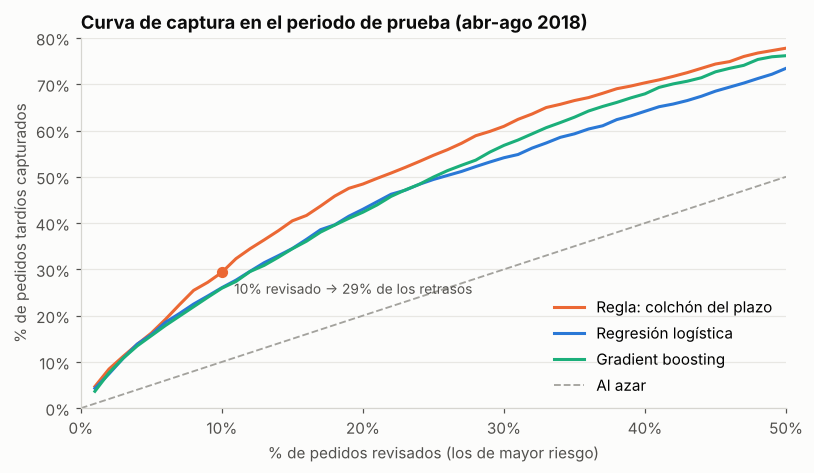

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ks = np.linspace(0.01, 0.5, 50)
palette = {rule_name: ORANGE, "Regresión logística": BLUE, "Gradient boosting": AQUA}
for name, s in test_scores.items():
    ax.plot(100 * ks, [100 * capture_at(y_test, s, k) for k in ks], color=palette[name], label=name)
ax.plot([0, 50], [0, 50], color=GRAY, linestyle="--", linewidth=1.2, label="Al azar")
cap_rule = capture_at(y_test, test_scores[rule_name], cfg.capacity)
ax.scatter([10], [100 * cap_rule], color=ORANGE, s=40, zorder=3)
ax.annotate(f"10% revisado → {cap_rule:.0%} de los retrasos", (10, 100 * cap_rule),
            textcoords="offset points", xytext=(8, -14), fontsize=9, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("% de pedidos revisados (los de mayor riesgo)")
ax.set_ylabel("% de pedidos tardíos capturados")
ax.set_title("Curva de captura en el periodo de prueba (abr-ago 2018)")
ax.legend(loc="lower right")
ax.set_xlim(0, 50)
ax.set_ylim(0, 80)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_capture_curve_test.png", dpi=160)

## 6. Backtest mes a mes

Un solo corte puede engañar. En cada mes, de octubre de 2017 a agosto de 2018, se repite el procedimiento completo:
1. se construyen las variables con priors anteriores a ese mes;
2. se entrena con todo lo que se conocía antes del mes;
3. se evalúa sobre las compras del mes.

In [7]:
backtest = []
for month in pd.date_range(cfg.backtest_first_month, "2018-08-01", freq="MS"):
    tr, ev = split_at(month, month + pd.offsets.MonthBegin(1))
    scores, _ = score_all(tr, ev, cfg.seed)
    y = ev[TARGET].to_numpy()
    for name, s in scores.items():
        backtest.append({"mes": month.strftime("%Y-%m"), "modelo": name, "pedidos": len(ev),
                         "tasa_tardios": y.mean(), "captura_top10": capture_at(y, s, cfg.capacity),
                         "auc_pr": average_precision_score(y, s)})
backtest = pd.DataFrame(backtest)
capture_by_month = backtest.pivot(index="mes", columns="modelo", values="captura_top10")
capture_by_month[[rule_name, "Regresión logística", "Gradient boosting"]].round(3)

modelo,Regla: colchón del plazo,Regresión logística,Gradient boosting
mes,,,
2017-10,0.214,0.191,0.164
2017-11,0.167,0.197,0.200
2017-12,0.203,0.179,0.141
2018-01,0.256,0.214,0.197
2018-02,0.310,0.270,0.166
2018-03,0.196,0.244,0.192
2018-04,0.279,0.326,0.262
2018-05,0.229,0.268,0.308
2018-06,0.333,0.289,0.333


In [8]:
summary = pd.DataFrame({
    "captura_top10_promedio": capture_by_month.mean(),
    "desv_estandar": capture_by_month.std(),
    "meses_que_supera_a_la_regla": (capture_by_month.gt(capture_by_month[rule_name], axis=0)).sum(),
}).loc[[rule_name, "Regresión logística", "Gradient boosting"]]
summary["meses_que_supera_a_la_regla"] = summary["meses_que_supera_a_la_regla"].astype(int)
summary.loc[rule_name, "meses_que_supera_a_la_regla"] = None
print(f"Meses evaluados: {capture_by_month.shape[0]}")
summary.round(3)

Meses evaluados: 11


,captura_top10_promedio,desv_estandar,meses_que_supera_a_la_regla
modelo,,,
Regla: colchón del plazo,0.247,0.051,NaN
Regresión logística,0.235,0.051,4.0
Gradient boosting,0.209,0.071,2.0


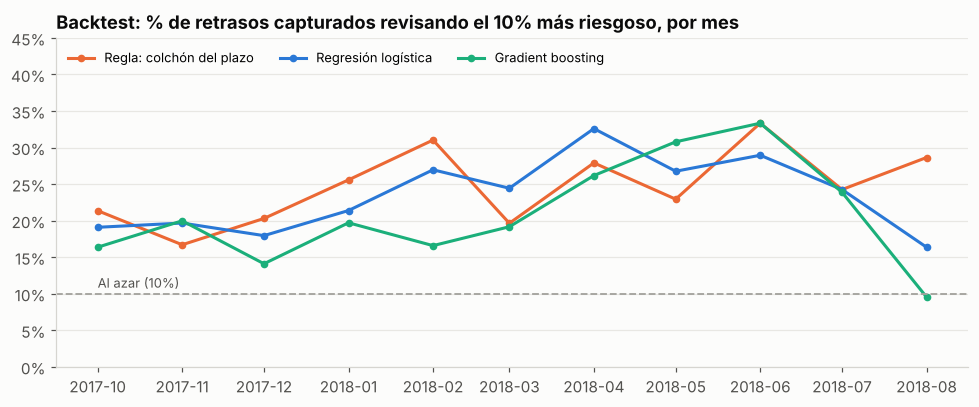

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
months = pd.to_datetime(capture_by_month.index)
for name in [rule_name, "Regresión logística", "Gradient boosting"]:
    ax.plot(months, 100 * capture_by_month[name], color=palette[name], marker="o", markersize=4, label=name)
ax.axhline(10, color=GRAY, linestyle="--", linewidth=1.2)
ax.annotate("Al azar (10%)", (months[0], 10), textcoords="offset points", xytext=(0, 4), fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, 45)
ax.set_title("Backtest: % de retrasos capturados revisando el 10% más riesgoso, por mes")
ax.legend(loc="upper left", ncol=3, fontsize=8.5)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_backtest_monthly_capture.png", dpi=160)

El backtest confirma lo que vimos en la prueba:

- **La regla tiene el mejor promedio:** 24.7% de captura, contra 23.5% de la regresión logística y 20.9% del gradient boosting. Los modelos la superan solo en 4 y 2 de 11 meses, respectivamente.
- **La regla es la más estable en el peor caso:** nunca baja de 16.7%.
- **El gradient boosting envejece mal:** en agosto de 2018, cuando los plazos prometidos se acortaron bruscamente, captura 9.5%, por debajo del azar. Es la señal típica de un modelo que aprendió patrones de una época que ya no existe.

## 7. ¿Qué aprendió el modelo? Importancia por permutación

Para el gradient boosting en el periodo de prueba: cuánto cae el AUC-PR si se revuelve cada variable al azar. Es una alternativa sin dependencias externas a SHAP, que mide la importancia en datos que el modelo no vio.

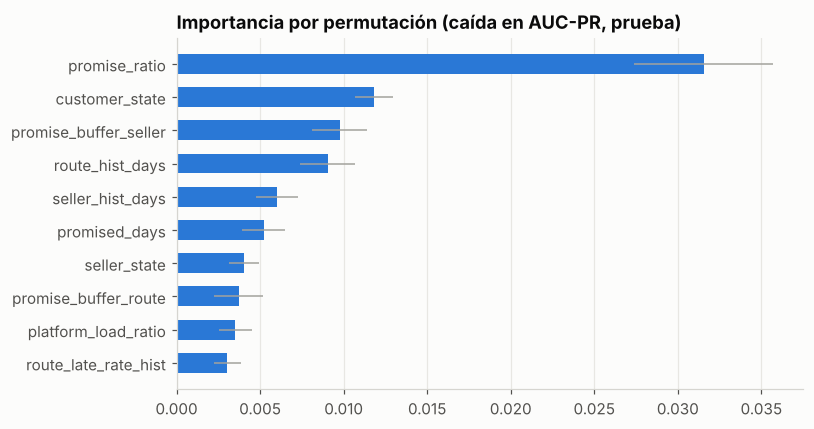

,variable,caida_auc_pr,desv
0,promise_ratio,0.0316,0.0042
1,customer_state,0.0118,0.0012
2,promise_buffer_seller,0.0098,0.0017
3,route_hist_days,0.0090,0.0016
4,seller_hist_days,0.0060,0.0013
5,promised_days,0.0052,0.0013
6,seller_state,0.0040,0.0009
7,promise_buffer_route,0.0037,0.0015
8,platform_load_ratio,0.0035,0.0010
9,route_late_rate_hist,0.0030,0.0008


In [10]:
_, test_boost = to_boosting_frame(train, test)
perm = permutation_importance(models["boosting"], test_boost, y_test, scoring="average_precision",
                              n_repeats=5, random_state=cfg.seed, n_jobs=-1)
importance = (pd.DataFrame({"variable": FEATURES, "caida_auc_pr": perm.importances_mean, "desv": perm.importances_std})
              .sort_values("caida_auc_pr", ascending=False).reset_index(drop=True))

top = importance.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(top.variable, top.caida_auc_pr, xerr=top.desv, color=BLUE, height=0.6,
        error_kw={"ecolor": GRAY, "elinewidth": 1})
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Importancia por permutación (caída en AUC-PR, prueba)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/06_permutation_importance.png", dpi=160)
importance.head(10).round(4)

El modelo complejo depende, por mucho, de la misma señal que usa la regla: `promise_ratio`. Su importancia es casi tres veces la de la siguiente variable. Le siguen el estado del cliente, el colchón por vendedor y lo que tarda la ruta.

El modelo no encuentra información adicional que compense el riesgo de memorizar el pasado; por eso no logra superar a la regla.

## 8. Política de operación: un umbral que se actualiza solo

Para operar día a día no se puede "tomar el 10% más riesgoso del mes" antes de que el mes termine. Hace falta un umbral que se conozca en el momento de la compra.

**Primer intento: un umbral fijo** calibrado en validación (el valor de `promise_ratio` que marcaba al 10% de los pedidos).

**Alternativa: un umbral móvil.** Cada día, el umbral es el percentil 10 de `promise_ratio` de los pedidos de los 30 días anteriores. Se actualiza solo, sin reentrenar nada.

In [11]:
fixed_threshold = float(np.quantile(val["promise_ratio"], cfg.capacity))
fixed_flag = test["promise_ratio"].to_numpy() < fixed_threshold

# Umbral móvil: percentil 10 de los 30 días previos (información disponible al comprar)
all_orders = build_features(df, cutoff=pd.Timestamp(cfg.test_start))[["purchase_ts", "promise_ratio"]]
daily_threshold = {}
for day in pd.date_range(cfg.test_start, pd.Timestamp(cfg.test_end) - pd.Timedelta(days=1), freq="D"):
    window = all_orders[(all_orders.purchase_ts >= day - pd.Timedelta(days=30)) & (all_orders.purchase_ts < day)]
    daily_threshold[day] = window.promise_ratio.quantile(cfg.capacity)
test_threshold = test.purchase_ts.dt.normalize().map(daily_threshold).to_numpy()
flag = test["promise_ratio"].to_numpy() < test_threshold

def describe_flag(name, f):
    return {"política": name, "% pedidos marcados": f.mean(), "% de retrasos capturados": y_test[f].sum() / y_test.sum(),
            "precisión": y_test[f].mean(), "veces la tasa base": y_test[f].mean() / y_test.mean()}

flag_table = pd.DataFrame([describe_flag(f"Umbral fijo (< {fixed_threshold:.2f})", fixed_flag),
                           describe_flag("Umbral móvil (p10 de los últimos 30 días)", flag)]).set_index("política")
print(f"Tasa base de retraso en prueba: {y_test.mean():.1%}")
flag_table.round(3)

Tasa base de retraso en prueba: 5.3%


,% pedidos marcados,% de retrasos capturados,precisión,veces la tasa base
política,,,,
Umbral fijo (< 1.24),0.178,0.454,0.135,2.551
Umbral móvil (p10 de los últimos 30 días),0.130,0.329,0.135,2.534


**El umbral fijo se desajusta:** marca el 17.8% de los pedidos en lugar del 10% planeado. La causa es que en 2018 Olist acortó sus promesas y bajó el `promise_ratio` de todos los pedidos.

**El umbral móvil se mantiene cerca de la capacidad:**
- marca el 13% de los pedidos y captura **el 33% de los retrasos**;
- el 13.5% de los marcados llega tarde, **2.5 veces la tasa base**;
- queda algo arriba del 10% porque las promesas se siguieron acortando durante la prueba, y la ventana de 30 días va un paso atrás.

Es la política recomendada para operar: no requiere reentrenar ni recalibrar a mano.

## 9. Recomendación cuantificada: un colchón mínimo en la fecha prometida

La acción más directa es no prometer menos de lo que la ruta realmente necesita. La política propuesta: si `promise_ratio` < r, se alarga la promesa hasta r × días históricos de la ruta.

Se simula en prueba con los días reales de entrega:

- **Pedido rescatado:** un pedido tardío que llegó antes de la nueva fecha prometida.
- **Costo:** los días extra que se prometen a los pedidos afectados.
- **Reseñas negativas evitadas (estimado):** para los pedidos rescatados, sus reseñas negativas reales menos las que tendría un pedido puntual (tasa negativa de los pedidos a tiempo en entrenamiento).

Los pedidos sin entrega no se pueden rescatar con más plazo; cuentan como no rescatados.

In [12]:
neg_rate_on_time = (train.loc[train[TARGET] == 0, "review_score"] <= 2).mean()
late_test = test[TARGET] == 1
policy_rows = []
for r in [1.3, 1.5, 1.7, 2.0]:
    affected = test["promise_ratio"] < r
    new_promise_days = np.ceil(r * test["route_hist_days"])
    extra_days = np.where(affected, np.maximum(new_promise_days - test["promised_days"], 0), 0)
    new_estimate = test["estimated_date"] + pd.to_timedelta(extra_days, unit="D")
    rescued = late_test & test["delivered_ts"].notna() & (test["delivered_ts"].dt.normalize() <= new_estimate)
    rescued_reviews = test.loc[rescued, "review_score"].dropna()
    negatives_avoided = (rescued_reviews <= 2).sum() - neg_rate_on_time * len(rescued_reviews)
    policy_rows.append({
        "colchón mínimo (r)": r,
        "% pedidos con promesa ajustada": affected.mean(),
        "días extra promedio (ajustados)": extra_days[affected].mean(),
        "días extra promedio (todos)": extra_days.mean(),
        "tardíos rescatados": int(rescued.sum()),
        "% de tardíos rescatados": rescued.sum() / late_test.sum(),
        "reseñas negativas evitadas (est.)": round(negatives_avoided),
    })
policy = pd.DataFrame(policy_rows).set_index("colchón mínimo (r)")
print(f"Pedidos tardíos en prueba: {late_test.sum():,} · Tasa negativa de pedidos a tiempo (entrenamiento): {neg_rate_on_time:.1%}")
policy.round(3)

Pedidos tardíos en prueba: 1,724 · Tasa negativa de pedidos a tiempo (entrenamiento): 9.5%


,% pedidos con promesa ajustada,días extra promedio (ajustados),días extra promedio (todos),tardíos rescatados,% de tardíos rescatados,reseñas negativas evitadas (est.)
colchón mínimo (r),,,,,,
1.3,0.216,3.579,0.772,398,0.231,85
1.5,0.343,4.670,1.604,607,0.352,164
1.7,0.473,5.952,2.814,779,0.452,236
2.0,0.658,8.047,5.299,982,0.570,339


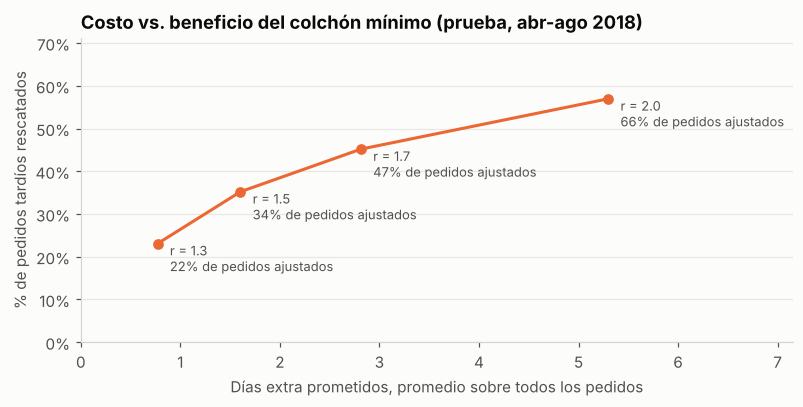

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(policy["días extra promedio (todos)"], 100 * policy["% de tardíos rescatados"], color=ORANGE, marker="o", markersize=6)
for r, row in policy.iterrows():
    ax.annotate(f"r = {r}\n{row['% pedidos con promesa ajustada']:.0%} de pedidos ajustados",
                (row["días extra promedio (todos)"], 100 * row["% de tardíos rescatados"]),
                textcoords="offset points", xytext=(8, -18), fontsize=8.5, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Días extra prometidos, promedio sobre todos los pedidos")
ax.set_ylabel("% de pedidos tardíos rescatados")
ax.set_title("Costo vs. beneficio del colchón mínimo (prueba, abr-ago 2018)")
ax.set_xlim(0, policy["días extra promedio (todos)"].max() * 1.35)
ax.set_ylim(0, 100 * policy["% de tardíos rescatados"].max() * 1.25)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/07_policy_tradeoff.png", dpi=160)

La tabla muestra el intercambio que tiene que decidir el negocio: cada punto extra de retrasos evitados cuesta días adicionales de promesa a una parte de los clientes.

- **Opción conservadora, r = 1.3:** ajusta la promesa del 22% de los pedidos, en promedio +3.6 días para esos pedidos (+0.8 sobre el total). **Rescata el 23% de los pedidos tardíos** (398 en cinco meses) y evita ~85 reseñas negativas.
- **Opción intermedia, r = 1.5:** rescata el 35% a cambio de +4.7 días para un tercio de los pedidos.

**Limitación importante:** alargar la promesa puede reducir la conversión (un cliente que ve "llega en 20 días" podría no comprar). Este dataset no permite medir ese efecto, porque solo trae pedidos ya comprados. Por eso la recomendación es aplicarlo como **prueba A/B**: un grupo con colchón mínimo y otro sin él, midiendo conversión y reseñas.

## 10. Exportar resultados

- **Predicciones del periodo de prueba** para la página "Riesgo" del dashboard.
- **Métricas del experimento** en JSON, para reproducibilidad.

In [14]:
predictions = test[["order_id", "purchase_ts", "main_seller_id", "customer_state", "seller_state", "route",
                    "promised_days", "route_hist_days", "promise_ratio", "is_late", "delivery_status"]].copy()
predictions["purchase_date"] = predictions.pop("purchase_ts").dt.date
predictions["late_probability"] = test_scores["Regresión logística"].round(4)
predictions["risk_percentile"] = (pd.Series(-test["promise_ratio"].to_numpy()).rank(pct=True).to_numpy() * 100).round(1)
predictions["flag_high_risk"] = flag.astype(int)
predictions = predictions.rename(columns={"main_seller_id": "seller_id"})
predictions.to_csv("../data/processed/test_predictions.csv", index=False)

run_meta = {
    "config": asdict(cfg),
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "test_late_rate": float(y_test.mean()),
    "validation": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in val_table.T.to_dict().items()},
    "test": {name: {m: round(float(v), 4) for m, v in metrics(y_test, s, cfg.capacity).items()} for name, s in test_scores.items()},
    "backtest_mean_capture_top10": {k: round(float(v), 4) for k, v in capture_by_month.mean().items()},
    "rule_threshold_fixed_promise_ratio": round(fixed_threshold, 4),
    "rule_threshold_rolling_test": {"flagged_share": round(float(flag.mean()), 4),
                            "capture": round(float(y_test[flag].sum() / y_test.sum()), 4),
                            "precision": round(float(y_test[flag].mean()), 4)},
    "promise_policy": {str(r): {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
                                for k, v in row.items()} for r, row in policy.iterrows()},
}
with open("../reports/model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(run_meta, f, ensure_ascii=False, indent=2)
print(f"{len(predictions):,} predicciones → data/processed/test_predictions.csv")
print("Métricas → reports/model_metrics.json")

32,453 predicciones → data/processed/test_predictions.csv
Métricas → reports/model_metrics.json


## Resumen del experimento

| | |
|---|---|
| **Datos** | 97,300 pedidos (2017-01 a 2018-08) con resultado de entrega conocido |
| **Corte** | Temporal: validación ene-mar 2018, prueba abr-ago 2018; backtest mensual oct 2017-ago 2018 |
| **Línea base** | Regla del colchón del plazo |
| **Resultado** | La regla captura 29.4% de los retrasos revisando 10% de los pedidos (IC 27.4–31.3%), ~3 veces el azar |
| **Modelos** | Regresión logística y gradient boosting quedan ~3.5 puntos debajo de la regla en prueba (diferencia significativa) |
| **Auditoría de fuga** | Historiales verificados por fuerza bruta; priors y codificadores ajustados solo con el pasado |
| **Decisión** | Operar con la regla (interpretable, sin reentrenamiento) y probar el colchón mínimo con una prueba A/B |